# 02 · Transfer learning

**Ementa 02** · Treinar uma CNN do zero (notebook 01) exige muitos exemplos rotulados — e temos poucos: 284 glaucomas, 266 DMRI.
*Transfer learning* reaproveita uma rede já treinada em outra tarefa com milhões de imagens (o **ImageNet**: 1,28 milhão de fotos, 1 000 classes)
e só adapta o final dela ao nosso problema. As primeiras camadas detectam bordas, texturas e manchas — úteis para qualquer imagem, inclusive retinas.

Neste notebook você vai: **(1)** ver o que uma rede do ImageNet "acha" de uma retinografia; **(2)** usar a rede congelada como
**extrator de características** e treinar só uma regressão logística em cima — para as três tarefas, em segundos; **(3)** fazer o **ajuste fino**
(*fine-tuning*) em duas fases; **(4)** medir **quanto dado** cada estratégia precisa; **(5)** ver, no espaço de características, por que
a validação externa vai importar.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import time
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from retina_iae import dados as D, metricas as Me, modelos as M, treino as T, visualizacao as V

V.configurar_estilo()
keras.utils.set_random_seed(0)
cache = D.Cache()
man = D.carregar_manifesto().set_index("id")

## 1. O que o ImageNet vê numa retina?

O EfficientNet-Lite0 deste projeto (`modelos.efficientnet_lite0_base`) foi **implementado camada a camada** e recebeu os pesos oficiais do
ImageNet (convertidos do `timm`; a diferença para a implementação de referência é < 10⁻⁶). Com a cabeça original de 1 000 classes,
ele classifica retinografias assim:

camadas com pesos carregados: 99


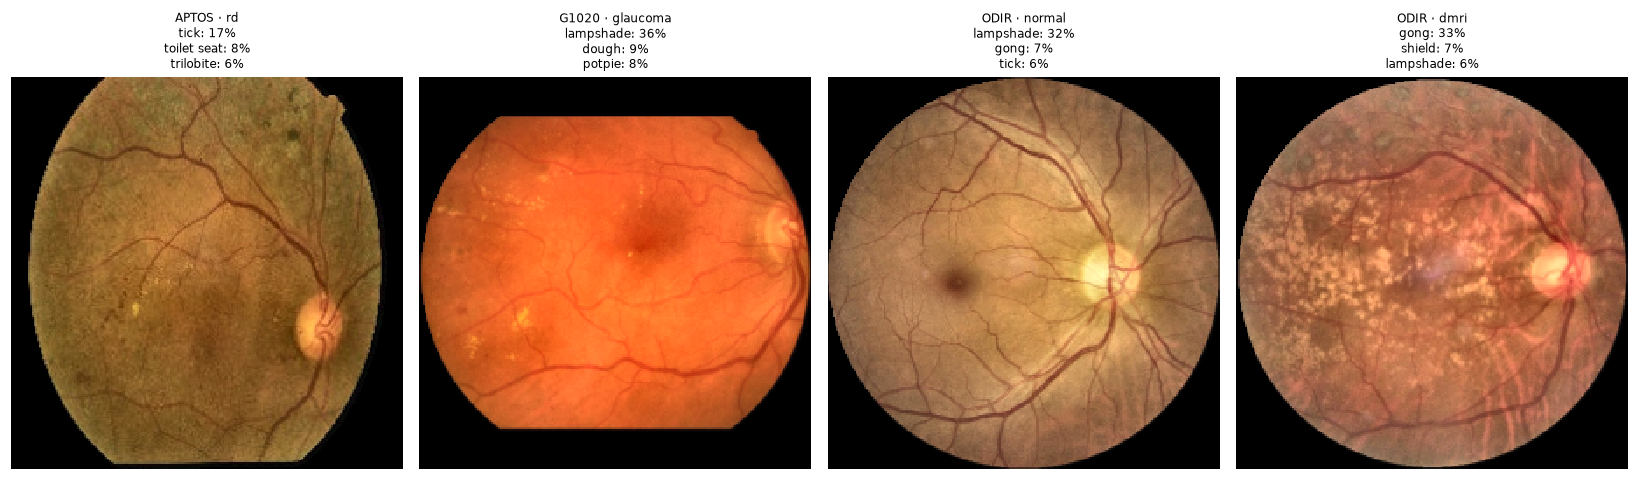

In [2]:
lite_imagenet = M.efficientnet_lite0_base(224, com_topo_imagenet=True)
print("camadas com pesos carregados:", M.carregar_pesos_lite0(lite_imagenet))
ids = ["aptos_0005", "g1020_0010", "odir_0001", man[man.condicao == "dmri"].index[3]]
X4 = cache[ids].astype(np.float32)
probs = lite_imagenet.predict(X4, verbose=0)
keras.utils.disable_interactive_logging()                          # sem barra de progresso no download dos nomes das classes
top = keras.applications.imagenet_utils.decode_predictions(probs, top=3)
keras.utils.enable_interactive_logging()
fig, axs = plt.subplots(1, 4, figsize=(15, 4.4))
for ax, i, t in zip(axs, ids, top):
    ax.imshow(cache[i]); ax.axis("off")
    ax.set_title(f"{man.loc[i, 'fonte']} · {man.loc[i, 'condicao']}\n" + "\n".join(f"{n.replace('_', ' ')}: {p:.0%}" for _, n, p in t), fontsize=8)
fig.tight_layout(); plt.show()

"Carrapato", "assento sanitário", "abajur", "gongo"… O ImageNet **não tem** a classe "retina" — mas para chegar a essas respostas a rede precisou detectar um disco
claro e redondo, bordas, texturas finas e gradientes de cor. São exatamente essas **características intermediárias** que vamos reaproveitar,
descartando a última camada (a das 1 000 classes).

## 2. Estratégia A — extrator de características congelado

Passamos cada imagem pela base congelada (sem a cabeça) e tiramos a **média global** do último mapa: um vetor de 576 números (MobileNetV3-Small)
ou 1 280 (EfficientNet-Lite0) por imagem — o *embedding*. Em cima dele, uma regressão logística. Nenhum peso da CNN muda; o treino leva segundos.

In [3]:
bases = {a: M.criar_base(a) for a in ["mobilenetv3_small", "efficientnet_lite0"]}
caracteristicas, tempos = {}, {}
part = D.carregar_particoes()
ids_todos = part.id.unique()
for nome, base in bases.items():
    t0 = time.time()
    emb = T.extrair_caracteristicas(base, cache[ids_todos])
    tempos[nome] = time.time() - t0
    caracteristicas[nome] = pd.DataFrame(emb, index=ids_todos)
    print(f"{nome:18s}: {emb.shape[1]:5d} características × {len(ids_todos):,} imagens em {tempos[nome]:.0f} s "
          f"({1e3 * tempos[nome] / len(ids_todos):.1f} ms/imagem)".replace(",", "."))

mobilenetv3_small :   576 características × 10.420 imagens em 23 s (2.2 ms/imagem)


efficientnet_lite0:  1280 características × 10.420 imagens em 74 s (7.1 ms/imagem)


In [4]:
def logistica(C=0.05):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000, class_weight="balanced"))

def avaliar_extrator(nome, tarefa):
    p = D.carregar_particoes(tarefa); f = caracteristicas[nome]
    tr, va, te = (p[p.particao == s] for s in ("treino", "validacao", "teste"))
    clf = logistica().fit(f.loc[tr.id], tr.alvo)
    return {"base": nome, "tarefa": tarefa,
            "AUC validação": Me.auc(va.alvo, clf.predict_proba(f.loc[va.id])[:, 1]),
            "AUC teste": Me.auc(te.alvo, clf.predict_proba(f.loc[te.id])[:, 1])}, clf

res_A = pd.DataFrame([avaliar_extrator(n, t)[0] for n in bases for t in D.TAREFAS])
res_A.pivot(index="tarefa", columns="base", values=["AUC validação", "AUC teste"]).round(3)

AUC validação                            AUC teste  \
base     efficientnet_lite0 mobilenetv3_small efficientnet_lite0   
tarefa                                                             
dmri                  0.828             0.827              0.807   
glaucoma              0.807             0.850              0.799   
rd                    0.971             0.976              0.967   

                            
base     mobilenetv3_small  
tarefa                      
dmri                 0.860  
glaucoma             0.793  
rd                   0.979

Com **zero** ajuste da CNN, uma regressão logística sobre características do ImageNet já separa bem a RD (AUC ≈ 0,97–0,98) e razoavelmente o
glaucoma e a DMRI (≈ 0,80–0,86). O EfficientNet-Lite0, 3,6× maior, **não** gera características melhores que o MobileNetV3-Small aqui — o tamanho
da rede só vai fazer diferença quando ela inteira for ajustada (notebook 03).

## 3. Estratégia B — ajuste fino em duas fases

Agora a CNN inteira participa do treino, com cuidado para não **destruir** o que ela já sabe:

1. **Cabeça** (4 épocas, taxa de aprendizado 10⁻³): base congelada, só a camada final aprende. Começar o ajuste fino com uma cabeça
   aleatória mandaria gradientes enormes e ruidosos para a base.
2. **Ajuste fino** (até 12 épocas, taxa 10⁻⁴): a base é descongelada e tudo aprende devagar.

Detalhe importante: a base é chamada com `training=False` (veja `modelos.criar_classificador`). Assim as camadas de **BatchNorm** continuam
usando as médias e variâncias do ImageNet; reestimá-las com lotes de 32 retinas desestabilizaria a rede.

Fazemos isso para RD com o MobileNetV3-Small *(≈ 5 min em CPU)*:

16 épocas em 228 s · melhor AUC de validação 0.985


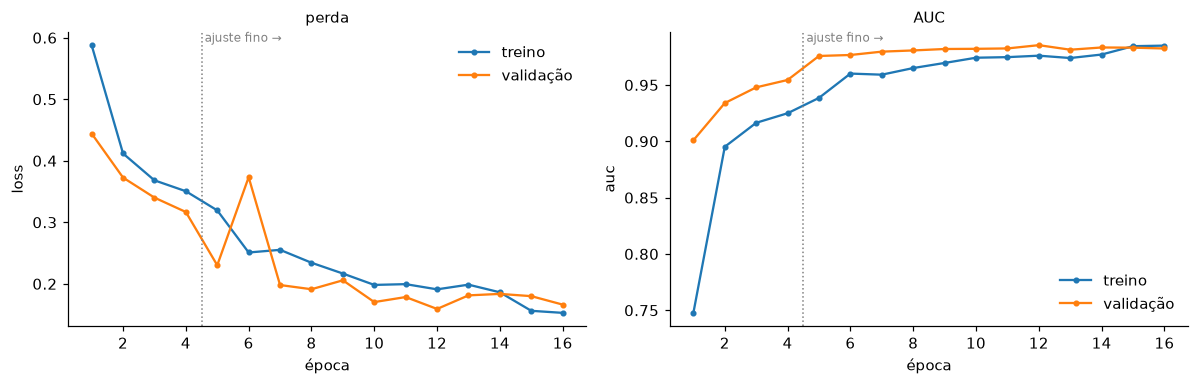

In [5]:
Xtr, ytr, _ = D.conjunto("rd", "treino", cache)
Xva, yva, _ = D.conjunto("rd", "validacao", cache)
Xte, yte, _ = D.conjunto("rd", "teste", cache)

t0 = time.time()
mft = M.criar_classificador("mobilenetv3_small")
hist_ft = T.treinar_duas_fases(mft, (Xtr, ytr), (Xva, yva), epocas_cabeca=4, epocas_ajuste=12, paciencia=4)
print(f"{len(hist_ft)} épocas em {time.time() - t0:.0f} s · melhor AUC de validação {hist_ft.val_auc.max():.3f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
V.historico(hist_ft, axs[0], "loss", "perda"); V.historico(hist_ft, axs[1], "auc", "AUC")
for a in axs: a.text(4.6, a.get_ylim()[1], "ajuste fino →", fontsize=8, color="gray", va="top")
fig.tight_layout(); V.salvar_figura(fig, "02_duas_fases"); plt.show()

In [6]:
Xdd, ydd, tdd = D.conjunto("rd", "externo", cache, fonte="DDR")
ids_te = D.conjunto("rd", "teste", cache)[2].id
clf_rd = avaliar_extrator("mobilenetv3_small", "rd")[1]
f_mn = caracteristicas["mobilenetv3_small"]
linhas = []
for nome, p_te, p_dd in [("ajuste fino (B)", T.prever(mft, Xte), T.prever(mft, Xdd)),
                         ("extrator congelado + logística (A)", clf_rd.predict_proba(f_mn.loc[ids_te])[:, 1],
                          clf_rd.predict_proba(f_mn.loc[tdd.id])[:, 1])]:
    a, lo, hi = Me.bootstrap(yte, p_te, Me.auc, n=500)
    b, blo, bhi = Me.bootstrap(ydd, p_dd, Me.auc, n=500)
    linhas.append({"MobileNetV3-Small · RD": nome, "AUC teste (APTOS)": round(a, 3), "IC teste": f"{lo:.3f}–{hi:.3f}",
                   "AUC externo (DDR)": round(b, 3), "IC DDR": f"{blo:.3f}–{bhi:.3f}"})
pd.DataFrame(linhas).set_index("MobileNetV3-Small · RD")

,AUC teste (APTOS),IC teste,AUC externo (DDR),IC DDR
MobileNetV3-Small · RD,,,,
ajuste fino (B),0.983,0.973–0.990,0.892,0.860–0.920
extrator congelado + logística (A),0.979,0.970–0.987,0.825,0.788–0.861


No teste interno, as duas estratégias **empatam** (os ICs se sobrepõem quase inteiros) — e empatam também com a CNN do zero do notebook 01.
A diferença aparece **no DDR**: o ajuste fino perde bem menos AUC numa câmera nova (≈ 0,89 contra ≈ 0,83 do extrator e ≈ 0,80 da CNN do zero).
Adaptar as características do ImageNet a microaneurismas, hemorragias e exsudatos rende pouco onde o modelo já era bom e **muito** onde ele é posto à prova.
É por isso que o notebook 03 usa ajuste fino.

## 4. Quanto dado cada estratégia precisa?

A pergunta prática para glaucoma e DMRI, que têm poucos positivos. Treinamos com frações crescentes do treino de RD (mesma validação)
e medimos a AUC de validação. Para caber no tempo, comparamos o **extrator congelado** (segundos) com a **CNN do zero** do notebook 01
(minutos). *(≈ 5–8 min.)*

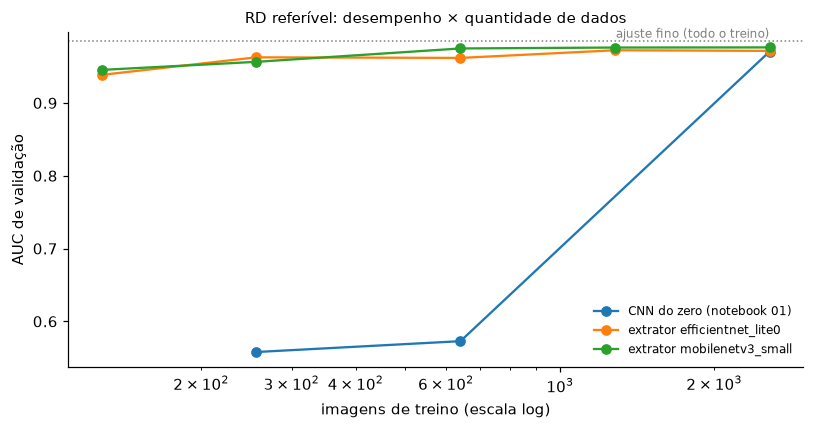

estratégia,CNN do zero (notebook 01),extrator efficientnet_lite0,extrator mobilenetv3_small
n treino,,,
128,NaN,0.939,0.945
256,0.558,0.963,0.956
640,0.573,0.962,0.975
1281,NaN,0.972,0.976
2563,0.971,0.971,0.976


In [7]:
p_rd = D.carregar_particoes("rd"); tr_rd = p_rd[p_rd.particao == "treino"].reset_index(drop=True)
va_rd = p_rd[p_rd.particao == "validacao"]
fracoes = [0.05, 0.1, 0.25, 0.5, 1.0]
linhas = []
for fr in fracoes:
    sub = tr_rd.groupby("alvo", group_keys=False).sample(frac=fr, random_state=0)
    for nome in bases:
        f = caracteristicas[nome]
        clf = logistica().fit(f.loc[sub.id], sub.alvo)
        linhas.append({"fração": fr, "n treino": len(sub), "estratégia": f"extrator {nome}",
                       "AUC validação": Me.auc(va_rd.alvo, clf.predict_proba(f.loc[va_rd.id])[:, 1])})
    if fr in (0.1, 0.25, 1.0):
        m0 = M.cnn_simples(128)
        h0 = T.treinar(m0, (cache[sub.id], sub.alvo.to_numpy(np.float32)), (Xva, yva), epocas=25, paciencia=5, tamanho=128)
        linhas.append({"fração": fr, "n treino": len(sub), "estratégia": "CNN do zero (notebook 01)", "AUC validação": h0.val_auc.max()})
curva = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(7.5, 4))
for nome, g in curva.groupby("estratégia"):
    ax.plot(g["n treino"], g["AUC validação"], "o-", label=nome)
ax.axhline(hist_ft.val_auc.max(), color="gray", ls=":", lw=1)
ax.text(curva["n treino"].max(), hist_ft.val_auc.max(), "ajuste fino (todo o treino)", fontsize=8, color="gray", ha="right", va="bottom")
ax.set_xscale("log"); ax.set_xlabel("imagens de treino (escala log)"); ax.set_ylabel("AUC de validação"); ax.legend(frameon=False, fontsize=8)
ax.set_title("RD referível: desempenho × quantidade de dados")
fig.tight_layout(); V.salvar_figura(fig, "02_curva_aprendizado"); plt.show()
curva.pivot(index="n treino", columns="estratégia", values="AUC validação").round(3)

Com **~ 130 imagens** (5 %), o extrator do ImageNet já passa de 0,93 — a CNN do zero, com 256 ou 640 imagens, mal sai do acaso e só alcança o
extrator com o treino inteiro (e varia muito de uma execução para outra com poucos dados). É por isso que, para
glaucoma e DMRI, transfer learning não é opção — é a única forma viável.

## 5. O espaço de características e o problema da câmera

Projetamos os *embeddings* do EfficientNet-Lite0 em 2D (PCA) e colorimos de dois jeitos: por **condição** e por **fonte**.

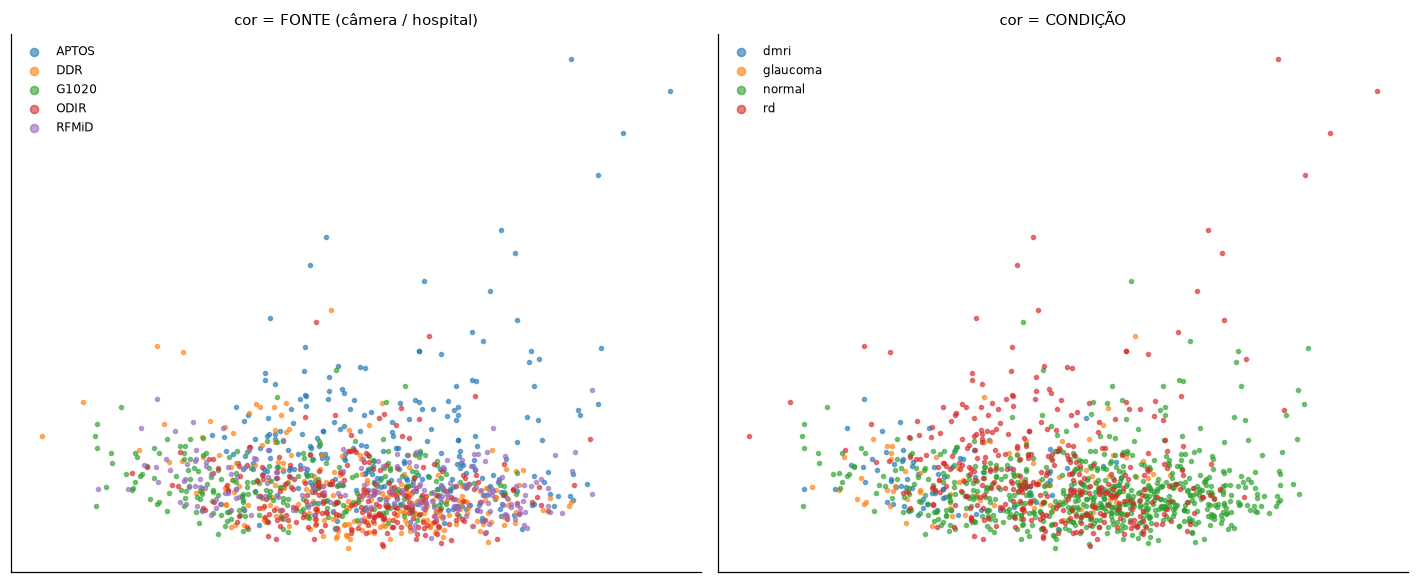

acurácia balanceada ao prever fonte (5 classes; acaso = 20 %): 80.8%


acurácia balanceada ao prever normal × doente (acaso = 50 %): 64.2%


In [8]:
from sklearn.decomposition import PCA
amostra = pd.concat([g.sample(min(len(g), 250), random_state=0) for _, g in D.carregar_manifesto().groupby("fonte")])
amostra = amostra[amostra.id.isin(caracteristicas["efficientnet_lite0"].index)]
z = PCA(2, random_state=0).fit_transform(StandardScaler().fit_transform(caracteristicas["efficientnet_lite0"].loc[amostra.id]))
fig, axs = plt.subplots(1, 2, figsize=(13, 5.4))
for col, ax, titulo in [("fonte", axs[0], "cor = FONTE (câmera / hospital)"), ("condicao", axs[1], "cor = CONDIÇÃO")]:
    for k, g in amostra.reset_index(drop=True).groupby(col):
        ax.scatter(z[g.index, 0], z[g.index, 1], s=7, alpha=0.6, label=k)
    ax.set_title(titulo); ax.legend(frameon=False, markerscale=2, fontsize=8); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); V.salvar_figura(fig, "02_pca_fontes"); plt.show()

# Quanto da FONTE está no embedding? Uma logística tenta adivinhar a fonte (5 classes) — validação cruzada, classes balanceadas
from sklearn.model_selection import cross_val_score
emb_amostra = caracteristicas["efficientnet_lite0"].loc[amostra.id]
for nome, alvo_ in [("fonte (5 classes; acaso = 20 %)", amostra.fonte), ("normal × doente (acaso = 50 %)", amostra.condicao != "normal")]:
    acc = cross_val_score(logistica(), emb_amostra, alvo_, cv=5, scoring="balanced_accuracy").mean()
    print(f"acurácia balanceada ao prever {nome}: {acc:.1%}")

No gráfico, só o APTOS se afasta visivelmente das demais fontes. Mas duas dimensões escondem muito: com os 1 280 números do embedding, uma regressão
logística **adivinha a fonte** de uma imagem com ≈ 81 % de acurácia balanceada (acaso: 20 %), enquanto distingue normal de doente com ≈ 64 % (acaso: 50 %).
Para uma rede do ImageNet, "de que câmera veio esta imagem" é informação **mais fácil** de extrair que "esta retina está doente". Consequências que guiam
o resto do módulo:

1. Um modelo treinado e testado na **mesma** fonte pode parecer excelente e cair numa câmera nova → **validação externa** (notebook 06).
2. Misturar fontes com prevalências diferentes no treino é perigoso: a rede pode aprender "câmera do hospital X → doença" (*atalho*).
   Por isso cada tarefa usa positivos e negativos da **mesma** fonte.
3. O retinógrafo do projeto é uma câmera nova: antes do uso, é preciso **validar nele** (ou recalibrar o limiar) — como os limiares de qualidade
   do Módulo 02.

## Resumo

| Estratégia | O que treina | Custo | Quando usar |
|---|---|---|---|
| do zero | todos os pesos, a partir do acaso | alto; precisa de muitos dados | dados abundantes e muito diferentes do ImageNet |
| extrator congelado | só a cabeça (ou uma logística) | segundos | poucos dados; primeira linha de base; protótipos |
| ajuste fino em duas fases | cabeça, depois a base com taxa baixa | minutos | o padrão deste módulo (notebook 03) |

## Exercícios propostos

1. **Glaucoma e DMRI com poucos dados.** Repita a curva da seção 4 para glaucoma e DMRI (só o extrator, rápido). A partir de quantas imagens
   positivas a AUC estabiliza?
2. **Quanto descongelar?** Em `treinar_duas_fases`, use `fracao_ajuste` = 0,25, 0,5 e 1,0. Compare AUC de validação e tempo por época.
3. **BatchNorm.** Crie um classificador cuja base é chamada com `training=True` (copie `criar_classificador` e mude uma linha) e faça o ajuste fino
   com lotes de 8. O que acontece com a curva de validação?
4. **Taxa de aprendizado.** Faça o ajuste fino com `lr_ajuste=1e-3` (10× maior). O que acontece com a AUC de validação nas primeiras épocas? Por quê?
5. **Atalho de propósito.** Monte um conjunto "RD" com positivos do APTOS e negativos do G1020 e treine o extrator. A AUC sai altíssima — o que o modelo
   aprendeu de verdade? Teste-o em positivos e negativos do DDR.